# Systemy AI – Laboratorium 7
## Zadanie: klasyfikator softmax w PyTorch – pingwiny

Napisz samodzielnie w PyTorch klasyfikator softmax, który rozpoznaje **gatunek pingwina** (Adelie, Chinstrap, Gentoo) na podstawie **dwóch** cech: długości i wysokości dzioba. Znasz te dane z Lab 4 – tym razem nie używasz gotowego `fit`, tylko sam(a) piszesz pętlę uczenia. Wzoruj się na notatniku `SystemyAI_Lab7_wzor.ipynb`.

Dwie cechy wybraliśmy celowo: wynik da się narysować na płaszczyźnie, a zadanie nie jest trywialne (Adelie i Chinstrap częściowo na siebie nachodzą).

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Dane → tensory
1. Wczytaj `sns.load_dataset("penguins")`, zostaw wiersze bez braków w `bill_length_mm`, `bill_depth_mm`, `species`.
2. Zamień gatunki na liczby: `gatunki = ["Adelie", "Chinstrap", "Gentoo"]` → 0, 1, 2.
3. Podział **trzyczęściowy** (dwa razy `train_test_split`, `stratify`, `random_state=42`): najpierw 20% na test, potem z reszty 25% na walidację. Wyjdzie 204 / 69 / 69.
4. `StandardScaler` dopasowany **tylko** na train; przekształć wszystkie trzy zbiory.
5. Tensory: `X_tr`, `X_va`, `X_te` (`float32`) oraz `y_tr`, `y_va`, `y_te` (`long`).

Zbiór walidacyjny posłuży do krzywych uczenia i wyboru learning rate, testowy – raz, na końcu.

In [1]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

df = sns.load_dataset("penguins").dropna(subset=["bill_length_mm", "bill_depth_mm", "species"])
gatunki = ["Adelie", "Chinstrap", "Gentoo"]
X = df[["bill_length_mm", "bill_depth_mm"]].values
y = df["species"].map({g: i for i, g in enumerate(gatunki)}).values
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=42
)
scaler = StandardScaler()
X_train_std = scaler.fit_transform(X_train)
X_val_std = scaler.transform(X_val)
X_test_std = scaler.transform(X_test)
X_tr = torch.tensor(X_train_std, dtype=torch.float32)
X_va = torch.tensor(X_val_std, dtype=torch.float32)
X_te = torch.tensor(X_test_std, dtype=torch.float32)
y_tr = torch.tensor(y_train, dtype=torch.long)
y_va = torch.tensor(y_val, dtype=torch.long)
y_te = torch.tensor(y_test, dtype=torch.long)
print("Rozmiary zbiorów:", X_tr.shape, X_va.shape, X_te.shape)

Rozmiary zbiorów: torch.Size([204, 2]) torch.Size([69, 2]) torch.Size([69, 2])


In [2]:
# TEST
assert X_tr.shape == (204, 2) and X_va.shape == (69, 2) and X_te.shape == (69, 2)
assert X_tr.dtype == torch.float32 and y_tr.dtype == torch.long
assert set(y_tr.tolist()) == {0, 1, 2}
assert torch.allclose(X_tr.mean(dim=0), torch.zeros(2), atol=1e-5), "Standaryzacja dopasowana na train"
print("1 OK")

1 OK


---
## 2. Model i strata przed uczeniem
1. `torch.manual_seed(0)`, potem `model = nn.Linear(2, 3)` i `loss_fn = nn.CrossEntropyLoss()`.
2. Policz `loss0` – stratę na zbiorze treningowym **przed** uczeniem (`.item()`).
3. Policz `p0` – prawdopodobieństwa (softmax) dla pierwszych 3 pingwinów treningowych i wypisz je.

In [3]:
# Twoje rozwiązanie
torch.manual_seed(0)
model = nn.Linear(2, 3)
loss_fn = nn.CrossEntropyLoss()
with torch.no_grad():
    loss0 = loss_fn(model(X_tr), y_tr).item()
    p0 = torch.softmax(model(X_tr[:3]), dim=1)
print(f"Strata przed uczeniem (loss0): {loss0:.4f} (ln 3 ≈ {np.log(3):.4f})")
print("Prawdopodobieństwa (p0) dla pierwszych 3 pingwinów treningowych:")
print(p0.numpy().round(4))

Strata przed uczeniem (loss0): 1.5298 (ln 3 ≈ 1.0986)
Prawdopodobieństwa (p0) dla pierwszych 3 pingwinów treningowych:
[[0.1938 0.5522 0.2539]
 [0.3298 0.3845 0.2857]
 [0.4144 0.2371 0.3485]]


In [4]:
# TEST
assert 0.8 < loss0 < 2.0
assert torch.allclose(p0.sum(dim=1), torch.ones(3))
print("2 OK")

2 OK


*Twoja odpowiedź:* model, który dla każdego pingwina daje wszystkim trzem gatunkom prawdopodobieństwo 1/3, ma stratę dokładnie ln 3 ≈ 1.10. Dlaczego? Czy twoja `loss0` jest blisko tej wartości?

Strata entropii krzyżowej to ujemny logarytm naturalny z prawdopodobieństwa prawdziwej klasy, czyli -ln(1/3), co jest równe ln 3, czyli około 1.10. Nasza strata loss0 wynosi około 1.53, więc jest dość blisko tej wartości, a jest trochę wyższa dlatego, że początkowe wagi są losowe i nie dają idealnie równych prawdopodobieństw 1/3.

---
## 3. Pętla uczenia
Napisz funkcję `train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va)`, która:
- ustawia `torch.manual_seed(seed)` i tworzy **nowy** `nn.Linear(2, 3)`, `CrossEntropyLoss` i `optim.SGD(..., lr=lr)`,
- uczy model mini-batchami (`DataLoader` z `shuffle=True`) przez `epochs` epok,
- po każdej epoce zapisuje w słowniku `historia` trzy listy: `"train loss"` (na `X`), `"val loss"` i `"val acc"` (na `X_val`); parametry `X` i `X_val` przydadzą się w punkcie 5,
- zwraca `(model, historia)`.

Uruchom ją dla `lr=0.1` (`model_01, hist_01`) i narysuj dwa wykresy: straty train/val oraz accuracy val w funkcji epoki.

Końcowa strata (val): 0.1492, accuracy (val): 0.9710


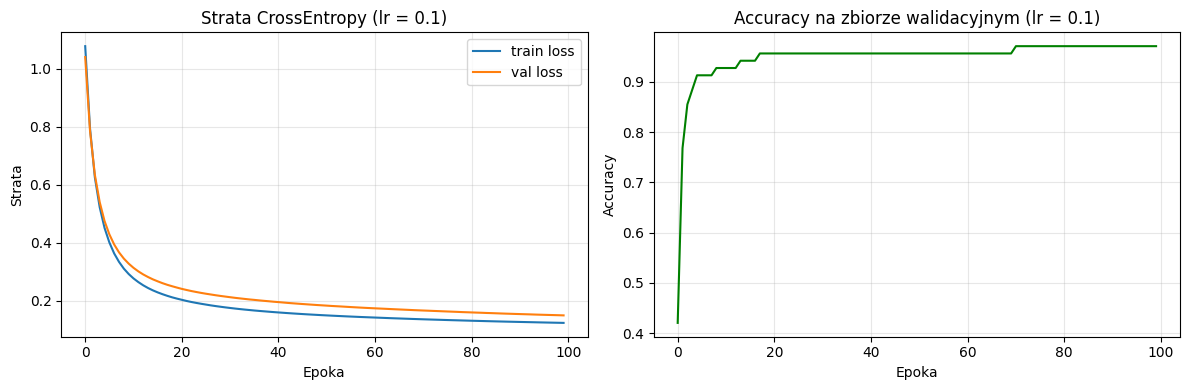

In [5]:
# Twoje rozwiązanie
def train(lr, epochs=100, batch_size=32, X=X_tr, seed=0, X_val=X_va):
    torch.manual_seed(seed)
    model = nn.Linear(X.shape[1], 3)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y_tr), batch_size=batch_size, shuffle=True)
    historia = {"train loss": [], "val loss": [], "val acc": []}
    for epoka in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        with torch.no_grad():
            historia["train loss"].append(loss_fn(model(X), y_tr).item())
            historia["val loss"].append(loss_fn(model(X_val), y_va).item())
            acc = (model(X_val).argmax(dim=1) == y_va).float().mean().item()
            historia["val acc"].append(acc)
    return model, historia
model_01, hist_01 = train(lr=0.1)
print(f"Końcowa strata (val): {hist_01['val loss'][-1]:.4f}, accuracy (val): {hist_01['val acc'][-1]:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_01["train loss"], label="train loss")
axes[0].plot(hist_01["val loss"], label="val loss")
axes[0].set_title("Strata CrossEntropy (lr = 0.1)")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Strata")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(hist_01["val acc"], color="green")
axes[1].set_title("Accuracy na zbiorze walidacyjnym (lr = 0.1)")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# TEST
assert set(hist_01) == {"train loss", "val loss", "val acc"} and len(hist_01["val acc"]) == 100
assert hist_01["train loss"][-1] < hist_01["train loss"][0], "Strata powinna maleć"
assert hist_01["val acc"][-1] > 0.9
print("3 OK")

3 OK


---
## 4. Learning rate
Naucz model dla `lr` ∈ {0.001, 0.01, 0.1, 1.0}. Na jednym wykresie narysuj krzywe **straty treningowej** dla wszystkich czterech wartości, a wyniki końcowe (`val loss`, `val acc` po 100 epokach) zbierz w `pd.DataFrame` o nazwie `wyniki_lr` (indeks: wartości lr).

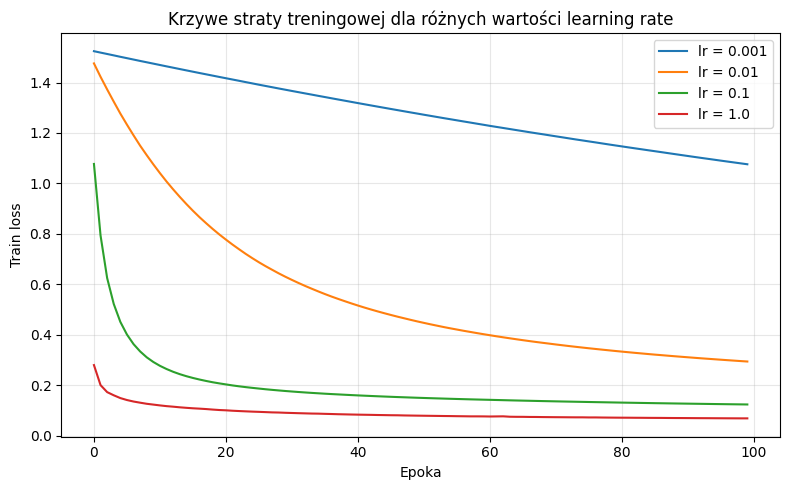

,val loss,val acc
lr,,
0.001,1.038211,0.420290
0.010,0.329397,0.927536
0.100,0.149183,0.971014
1.000,0.072390,0.971014


In [7]:
# Twoje rozwiązanie
lrs = [0.001, 0.01, 0.1, 1.0]
modele_lr = {}
wiersze = []
fig, ax = plt.subplots(figsize=(8, 5))
for lr in lrs:
    m, h = train(lr=lr)
    modele_lr[lr] = (m, h)
    ax.plot(h["train loss"], label=f"lr = {lr}")
    wiersze.append({"val loss": h["val loss"][-1], "val acc": h["val acc"][-1]})
ax.set_title("Krzywe straty treningowej dla różnych wartości learning rate")
ax.set_xlabel("Epoka")
ax.set_ylabel("Train loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
wyniki_lr = pd.DataFrame(wiersze, index=lrs)
wyniki_lr.index.name = "lr"
display(wyniki_lr)

In [8]:
# TEST
assert list(wyniki_lr.index) == [0.001, 0.01, 0.1, 1.0]
assert wyniki_lr.loc[0.001, "val loss"] > wyniki_lr.loc[0.1, "val loss"]
print("4 OK")

4 OK


*Twoja odpowiedź:* co widać dla lr = 0.001? Który learning rate wybierasz i na podstawie którego zbioru?

Dla lr = 0.001 kroki uczenia są za małe, więc strata maleje bardzo wolno i po 100 epokach model nadal ma duży błąd (val loss ponad 1.03 i accuracy tylko 42%). Wybieram lr = 0.1 (ewentualnie 1.0), ponieważ daje wysokie accuracy (97.1%) i niską stratę przy stabilnym przebiegu uczenia. Wyboru dokonuję na podstawie zbioru walidacyjnego.

---
## 5. Co daje standaryzacja?
Utwórz `X_tr_raw` i `X_va_raw` – tensory **bez** standaryzacji (surowe milimetry z `X_train`, `X_val`) i naucz model z `lr=0.1`: `train(0.1, X=X_tr_raw, X_val=X_va_raw)`. Porównaj końcową stratę i accuracy z wynikiem z punktu 3. Wynik zapisz w `hist_raw`.

Ze standaryzacją (pkt 3) -> val loss: 0.1492, val acc: 0.9710
Bez standaryzacji (raw)  -> val loss: 1.6196, val acc: 0.9420


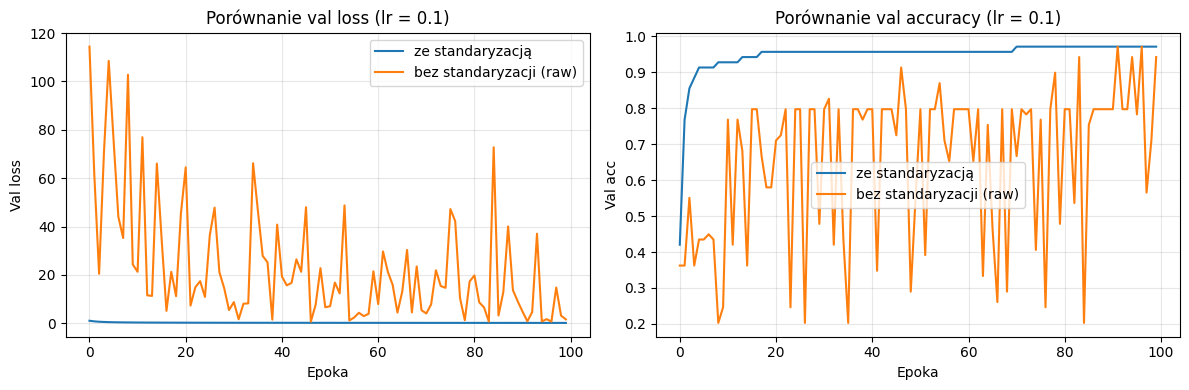

In [9]:
# Twoje rozwiązanie
X_tr_raw = torch.tensor(X_train, dtype=torch.float32)
X_va_raw = torch.tensor(X_val, dtype=torch.float32)
model_raw, hist_raw = train(0.1, X=X_tr_raw, X_val=X_va_raw)
print(f"Ze standaryzacją (pkt 3) -> val loss: {hist_01['val loss'][-1]:.4f}, val acc: {hist_01['val acc'][-1]:.4f}")
print(f"Bez standaryzacji (raw)  -> val loss: {hist_raw['val loss'][-1]:.4f}, val acc: {hist_raw['val acc'][-1]:.4f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_01["val loss"], label="ze standaryzacją")
axes[0].plot(hist_raw["val loss"], label="bez standaryzacji (raw)")
axes[0].set_title("Porównanie val loss (lr = 0.1)")
axes[0].set_xlabel("Epoka")
axes[0].set_ylabel("Val loss")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(hist_01["val acc"], label="ze standaryzacją")
axes[1].plot(hist_raw["val acc"], label="bez standaryzacji (raw)")
axes[1].set_title("Porównanie val accuracy (lr = 0.1)")
axes[1].set_xlabel("Epoka")
axes[1].set_ylabel("Val acc")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# TEST
assert hist_raw["val acc"][-1] < hist_01["val acc"][-1]
print("5 OK")

5 OK


*Twoja odpowiedź:* dlaczego bez standaryzacji uczenie idzie tak źle, choć model i dane są te same?

Surowe cechy w milimetrach mają duże wartości liczbowe, przez co obliczane gradienty też są bardzo duże. Przy lr = 0.1 aktualizacje wag robią za duże kroki, model przeskakuje minimum funkcji straty i wykres straty mocno skacze zamiast spokojnie maleć.

---
## 6. Ocena końcowa i porównanie ze scikit-learn
1. Wybierz model z punktu 4 (wybór na podstawie walidacji) i zapisz go jako `model_koncowy`. Policz `acc_test` – accuracy na **teście**.
2. Naucz `LogisticRegression()` ze scikit-learn na tych samych wystandaryzowanych danych treningowych i policz jej accuracy na teście: `acc_sk`.
3. Wypisz prawdopodobieństwa (softmax) Twojego modelu dla pierwszych 5 pingwinów testowych, z nazwami gatunków i prawdziwym gatunkiem.
4. Narysuj obszary decyzyjne `model_koncowy` na płaszczyźnie (wystandaryzowane cechy) z punktami treningowymi – możesz skopiować funkcję `granica` z wzoru.

Accuracy na teście (PyTorch):      0.9275
Accuracy na teście (scikit-learn): 0.9275

Prawdopodobieństwa (softmax) dla pierwszych 5 pingwinów testowych:


,Adelie,Chinstrap,Gentoo,Przewidziany gatunek,Prawdziwy gatunek
0,0.9119,0.0847,0.0034,Adelie,Adelie
1,0.9602,0.0309,0.0089,Adelie,Adelie
2,0.0026,0.0240,0.9734,Gentoo,Gentoo
3,0.0468,0.0896,0.8636,Gentoo,Gentoo
4,0.2572,0.6798,0.0630,Chinstrap,Chinstrap


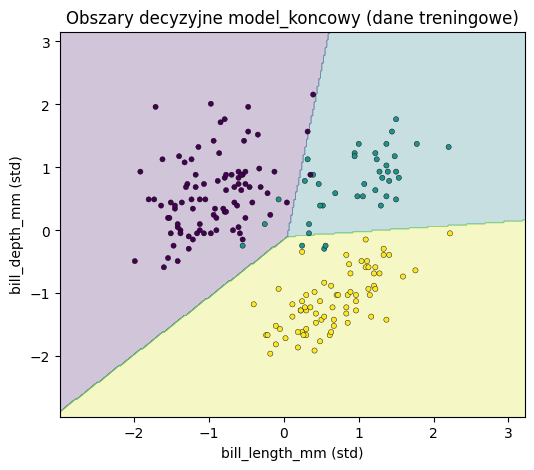

In [11]:
# Twoje rozwiązanie
model_koncowy = modele_lr[0.1][0]
with torch.no_grad():
    acc_test = (model_koncowy(X_te).argmax(dim=1) == y_te).float().mean().item()
    p_test = torch.softmax(model_koncowy(X_te[:5]), dim=1)
sk = LogisticRegression().fit(X_tr.numpy(), y_tr.numpy())
acc_sk = sk.score(X_te.numpy(), y_te.numpy())
print(f"Accuracy na teście (PyTorch):      {acc_test:.4f}")
print(f"Accuracy na teście (scikit-learn): {acc_sk:.4f}\n")
df_p_test = pd.DataFrame(p_test.numpy().round(4), columns=gatunki)
df_p_test["Przewidziany gatunek"] = [gatunki[i] for i in p_test.argmax(dim=1).tolist()]
df_p_test["Prawdziwy gatunek"] = [gatunki[i] for i in y_te[:5].tolist()]
print("Prawdopodobieństwa (softmax) dla pierwszych 5 pingwinów testowych:")
display(df_p_test)
def granica(model, X, y, tytul, softmax=False):
    """Rysuje obszary decyzyjne modelu na płaszczyźnie i punkty danych."""
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
    siatka = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        out = model(siatka)
        Z = out.argmax(dim=1) if softmax else (out > 0).squeeze(1)
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.contourf(xx, yy, Z.reshape(xx.shape).numpy(), alpha=0.25, cmap="viridis")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=14, cmap="viridis", edgecolors="k", linewidths=0.3)
    ax.set_title(tytul)
    ax.set_xlabel("bill_length_mm (std)")
    ax.set_ylabel("bill_depth_mm (std)")
    plt.show()
granica(model_koncowy, X_tr.numpy(), y_tr.numpy(), "Obszary decyzyjne model_koncowy (dane treningowe)", softmax=True)

In [12]:
# TEST
assert 0.85 < acc_test <= 1.0
assert abs(acc_test - acc_sk) <= 0.06, "Ten sam model - wyniki powinny być bardzo podobne"
assert torch.allclose(p_test.sum(dim=1), torch.ones(5))
print("6 OK")

6 OK


*Twoja odpowiedź:*
1. Jak wypada Twój model w porównaniu ze scikit-learn? Czy to zaskakujące?
2. Gdzie leżą błędy modelu na wykresie obszarów decyzyjnych? Czy model liniowy mógłby tu zrobić coś lepiej?
3. Wymień kroki pętli uczenia i powiedz jednym zdaniem, co robi każdy z nich.

1 Oba modele uzyskały na zbiorze testowym identyczne accuracy równe 0.9275. Nie jest to zaskakujące, bo oba uczą dokładnie ten sam model liniowy z tą samą funkcją straty.

2 Błędy leżą na granicy między gatunkami, głównie tam, gdzie punkty Adelie i Chinstrap nachodzą na siebie. Model liniowy rysuje tylko proste linie podziału, więc przy nachodzących na siebie punktach nie da się poprowadzić prostej, która oddzieli je bezbłędnie.

3 Kroki pętli uczenia:
model(xb) - oblicza przewidywania modelu (logity) dla paczki danych.
loss_fn(...) - oblicza stratę, czyli jak bardzo model się pomylił.
optimizer.zero_grad() - zeruje gradienty z poprzedniego kroku, żeby się nie sumowały.
loss.backward() - oblicza gradienty straty względem wag modelu.
optimizer.step() - poprawia wagi modelu o krok w kierunku przeciwnym do gradientu.

---
## 7. Dla chętnych
1. **Batch size:** naucz model z `lr=0.1` dla `batch_size` ∈ {8, 32, 204} (204 = cały zbiór naraz). Porównaj krzywe straty. Który wariant robi najwięcej kroków w epoce? Który uczy się najszybciej w przeliczeniu na epoki?
2. **Adam:** zamień `optim.SGD` na `optim.Adam` (lr = 0.01) i porównaj krzywe z SGD.
3. **Więcej cech:** dodaj `flipper_length_mm` i `body_mass_g` (`nn.Linear(4, 3)`). Ile zyskuje accuracy?

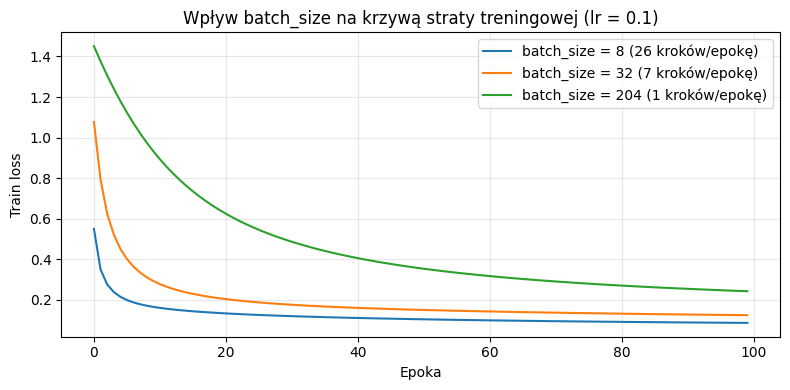

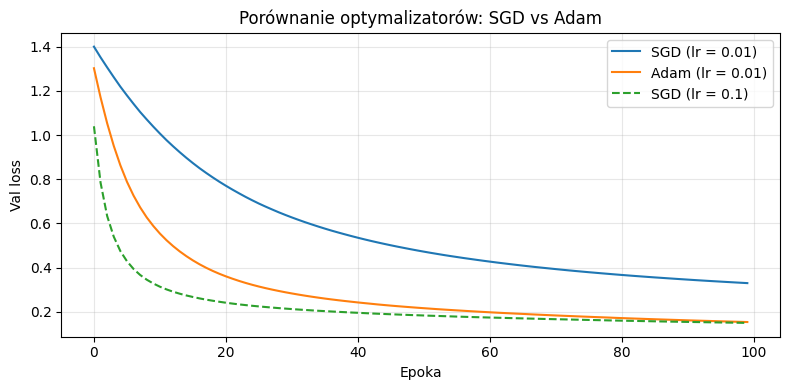

Accuracy na teście dla 2 cech: 0.9275
Accuracy na teście dla 4 cech: 1.0000 (zysk: +7.25 p.p.)


In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
for bs in [8, 32, 204]:
    _, h_bs = train(lr=0.1, batch_size=bs)
    kroki = int(np.ceil(len(X_tr) / bs))
    ax.plot(h_bs["train loss"], label=f"batch_size = {bs} ({kroki} kroków/epokę)")
ax.set_title("Wpływ batch_size na krzywą straty treningowej (lr = 0.1)")
ax.set_xlabel("Epoka")
ax.set_ylabel("Train loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
# Najwięcej kroków w epoce (26) wykonuje batch_size=8 i to on najszybciej obniża stratę w przeliczeniu na epoki.
def train_adam(lr=0.01, epochs=100, batch_size=32, seed=0):
    torch.manual_seed(seed)
    m = nn.Linear(2, 3)
    loss_fn = nn.CrossEntropyLoss()
    opt = optim.Adam(m.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=batch_size, shuffle=True)
    hist = {"train loss": [], "val loss": [], "val acc": []}
    for _ in range(epochs):
        for xb, yb in loader:
            loss = loss_fn(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        with torch.no_grad():
            hist["train loss"].append(loss_fn(m(X_tr), y_tr).item())
            hist["val loss"].append(loss_fn(m(X_va), y_va).item())
            hist["val acc"].append((m(X_va).argmax(dim=1) == y_va).float().mean().item())
    return m, hist
_, hist_adam = train_adam(lr=0.01)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(modele_lr[0.01][1]["val loss"], label="SGD (lr = 0.01)")
ax.plot(hist_adam["val loss"], label="Adam (lr = 0.01)")
ax.plot(hist_01["val loss"], label="SGD (lr = 0.1)", linestyle="--")
ax.set_title("Porównanie optymalizatorów: SGD vs Adam")
ax.set_xlabel("Epoka")
ax.set_ylabel("Val loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
cechy4 = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
df4 = sns.load_dataset("penguins").dropna(subset=cechy4 + ["species"])
X4 = df4[cechy4].values
y4 = df4["species"].map({g: i for i, g in enumerate(gatunki)}).values
X4_rest, X4_test, y4_rest, y4_test = train_test_split(X4, y4, test_size=0.2, stratify=y4, random_state=42)
X4_train, X4_val, y4_train, y4_val = train_test_split(X4_rest, y4_rest, test_size=0.25, stratify=y4_rest, random_state=42)
sc4 = StandardScaler()
X4_tr = torch.tensor(sc4.fit_transform(X4_train), dtype=torch.float32)
X4_va = torch.tensor(sc4.transform(X4_val), dtype=torch.float32)
X4_te = torch.tensor(sc4.transform(X4_test), dtype=torch.float32)
model_4cechy, hist_4cechy = train(lr=0.1, X=X4_tr, X_val=X4_va)
with torch.no_grad():
    acc_test_4 = (model_4cechy(X4_te).argmax(dim=1) == y_te).float().mean().item()
print(f"Accuracy na teście dla 2 cech: {acc_test:.4f}")
print(f"Accuracy na teście dla 4 cech: {acc_test_4:.4f} (zysk: +{(acc_test_4 - acc_test)*100:.2f} p.p.)")